# End-to-End Dropout Risk Prediction & Deployment for Higher Education

**Client:** Aegis Education Solutions (EdTech platform serving 50+ universities)
**Your role:** Lead Machine Learning Developer
**Dataset:** `academic_survival_longitudinal.csv` (79,239 rows × 22 columns)

---

#### The business problem in one paragraph
Up to **10% of students drop out** before finishing their programmes. Today, advisors only react to *lagging* signals (failed mid-terms, end-of-semester grades), and by then it is usually too late to help. Aegis wants a model that looks at a student's current semester (academic, financial and engagement data) and **predicts whether they will drop out before next semester**, so advisors can step in early.

#### What we will build (the 5 workflow steps from the case study)

| Step | What we do | Key tools |
|---|---|---|
| 1 | Data exploration & cleansing | `pandas` |
| 2 | Preprocessing pipeline (impute, scale, encode) | `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline` |
| 3 | Model training & optimisation (with class weighting) | `RandomForestClassifier`, `GridSearchCV` |
| 4 | Evaluation & interpretability | `classification_report`, confusion matrix, ROC-AUC, feature importance |
| 5 | Deployment as an interactive web app | `gradio` |

In [ ]:
# !pip install gradio

In [1]:
# ---------- Core data libraries ----------
import numpy as np                 # numerical computing (arrays, maths)
import pandas as pd                # tables / DataFrames
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # statistical plotting, nicer defaults

# ---------- scikit-learn: data splitting & tuning ----------
from sklearn.model_selection import train_test_split   # splits data into training and  test set
from sklearn.model_selection import GridSearchCV      # tries many model settings and picks the best

# ---------- scikit-learn: preprocessing building blocks ----------
from sklearn.compose import ColumnTransformer     # applies different steps to different columns
from sklearn.pipeline import Pipeline    # chains steps together into one object
from sklearn.impute import SimpleImputer     # fills in missing values
from sklearn.preprocessing import StandardScaler    # puts numbers on the same scale
from sklearn.preprocessing import OneHotEncoder   # converts text categories into 0/1 columns

# ---------- scikit-learn: models ----------
from sklearn.ensemble import RandomForestClassifier

# ---------- scikit-learn: evaluation metrics ----------
from sklearn.metrics import classification_report   # precision, recall, f1 per class
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay     # table of right vs wrong predictions
from sklearn.metrics import roc_auc_score     # how well the model ranks risky vs safe students

#------ Deployment----------
import gradio as gr  

# Make charts look clean and consistent
sns.set_style('whitegrid')

C:\Users\user\anaconda\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\user\anaconda\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


---
## STEP 1: Data Exploration & Cleansing

### 1.1 Load the dataset 

In [2]:
# Read the CSV file into a DataFrame called df.
# The file must be in the same folder as this notebook (or give the full path).
df = pd.read_csv('academic_survival_longitudinal.csv')

#View first 5 rows
df.head()

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [3]:
# List all column names
df.columns

Index(['Student_ID', 'Age', 'Gender', 'First_Generation', 'Family_Income',
       'Household_Size', 'Housing_Status', 'Scholarship', 'Tuition_Base',
       'Semester', 'Course_Load', 'Work_Hours', 'Emergency_Expense', 'Sem_GPA',
       'Attendance', 'LMS_Logins', 'Advising_Visits', 'Failed_Courses',
       'Financial_Stress', 'Target_Dropout_Next_Sem', 'End_of_Semester_Status',
       'Censored'],
      dtype='str')

In [4]:
# Convert column names to lowercase
df.columns = df.columns.str.lower()

df.columns

Index(['student_id', 'age', 'gender', 'first_generation', 'family_income',
       'household_size', 'housing_status', 'scholarship', 'tuition_base',
       'semester', 'course_load', 'work_hours', 'emergency_expense', 'sem_gpa',
       'attendance', 'lms_logins', 'advising_visits', 'failed_courses',
       'financial_stress', 'target_dropout_next_sem', 'end_of_semester_status',
       'censored'],
      dtype='str')

##### Shape, data types and missing values

In [5]:
# Dimension of the data - Rows, columns
df.shape

(79239, 22)

In [6]:
# column datatype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               79239 non-null  str    
 1   age                      79239 non-null  int64  
 2   gender                   79239 non-null  str    
 3   first_generation         79239 non-null  int64  
 4   family_income            75635 non-null  float64
 5   household_size           79239 non-null  int64  
 6   housing_status           79239 non-null  str    
 7   scholarship              79239 non-null  int64  
 8   tuition_base             79239 non-null  int64  
 9   semester                 79239 non-null  int64  
 10  course_load              79239 non-null  int64  
 11  work_hours               79239 non-null  float64
 12  emergency_expense        79239 non-null  float64
 13  sem_gpa                  79239 non-null  float64
 14  attendance               79239 no

In [8]:
# Count fully duplicated rows (True = duplicate, and summing Trues counts them)
df.duplicated().sum()

0

In [9]:
# Count missing values per columns
df.isna().sum()

student_id                    0
age                           0
gender                        0
first_generation              0
family_income              3604
household_size                0
housing_status                0
scholarship                   0
tuition_base                  0
semester                      0
course_load                   0
work_hours                    0
emergency_expense             0
sem_gpa                       0
attendance                    0
lms_logins                  867
advising_visits               0
failed_courses                0
financial_stress              0
target_dropout_next_sem       0
end_of_semester_status        0
censored                      0
dtype: int64

In [10]:
# How many students fall in each admin status - end of semester status
df['end_of_semester_status'].value_counts()

end_of_semester_status
Enrolled       70354
Dropped_Out     6917
Graduated       1968
Name: count, dtype: int64

In [11]:
df['censored'].value_counts()

censored
0    68124
1    11115
Name: count, dtype: int64

##### Data Quality Check and Handling

In [12]:
print(df['gender'].value_counts(), '\n')
print(df['housing_status'].value_counts())

gender
Female               38035
Male                 36556
Other                 1125
female                 875
male                   764
M                      739
F                      716
Prefer not to say      429
Name: count, dtype: int64 

housing_status
On-Campus       31315
With Parents    24767
Off-Campus      23157
Name: count, dtype: int64


In [14]:
# A "mapping" dictionary: messy version (lowercased)  ->  clean version (current state: new state)
gender_map = {
    'f': 'Female', 'female':'Female',
    'm': 'Male', 'male': 'Male',
}

df['gender'] = (df['gender'].str.strip().str.lower().map(gender_map).fillna(df['gender']))

# same for housing_status
df['housing_status'] = df['housing_status'].str.strip()

# Check result
print(df['gender'].value_counts(), '\n')
print(df['housing_status'].value_counts())

gender
Female               39626
Male                 38059
Other                 1125
Prefer not to say      429
Name: count, dtype: int64 

housing_status
On-Campus       31315
With Parents    24767
Off-Campus      23157
Name: count, dtype: int64


#### Separate Features (X) and Target (y)

In [15]:
# The column to predict
target = 'target_dropout_next_sem'

# Columns that must NOT be used as inputs (ID, the target itself, and the two leakage columns)
columns_to_exclude = ['student_id', target , 'end_of_semester_status', 'censored']

# List - all columns excluding those mentioned above
features = [col for col in df.columns if col not in columns_to_exclude]

# define X and y
X = df[features]   # inputs table: 18 predictor columns 
y = df[target]    # output column (what we are predicting)

print(f'Number of features: {len(features)}')
print(features)

Number of features: 18
['age', 'gender', 'first_generation', 'family_income', 'household_size', 'housing_status', 'scholarship', 'tuition_base', 'semester', 'course_load', 'work_hours', 'emergency_expense', 'sem_gpa', 'attendance', 'lms_logins', 'advising_visits', 'failed_courses', 'financial_stress']


#### Check the class balance of the target

In [20]:
# View target values
print(y.value_counts(), '/n')

# percentage view
print((y.value_counts(normalize=True) * 100).round(2))

target_dropout_next_sem
0    72322
1     6917
Name: count, dtype: int64 /n
target_dropout_next_sem
0    91.27
1     8.73
Name: proportion, dtype: float64


#### Separate numerical and categorical columns

In [19]:
# Numerical - int, float
num_col = X.select_dtypes(include='number').columns.tolist()

# Cat
cat_col = X.select_dtypes(exclude='number').columns.tolist()

print('Numerical columns: ', num_col)
print('Categorical columns: ', cat_col)

Numerical columns:  ['age', 'first_generation', 'family_income', 'household_size', 'scholarship', 'tuition_base', 'semester', 'course_load', 'work_hours', 'emergency_expense', 'sem_gpa', 'attendance', 'lms_logins', 'advising_visits', 'failed_courses', 'financial_stress']
Categorical columns:  ['gender', 'housing_status']


#### Split Dataset into Train and Test Set

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify = y)

# View result
print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)

# Check stratification worked: both should be about 8.7% dropout
print(f'Dropout rate in train: {y_train.mean():.3%}')
print(f'Dropout rate in test : {y_test.mean():.3%}')

Train shape: (63391, 18)
Test shape : (15848, 18)
Dropout rate in train: 8.730%
Dropout rate in test : 8.727%


## STEP 2: Preprocessing Pipeline Construction

#### Numerical Transformer

In [24]:
# Mini-pipeline for numerical col

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

#### Categorical Transformer

In [25]:
# Mini-pipeline for categorical col
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [26]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_col),
    ('cat', cat_transformer, cat_col)
])

#### Full end-to-end pipeline (preprocessing + model) - Random Forest Classifier

In [28]:
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators =100, random_state=42, class_weight='balanced'))
])

#displaying the object as a visual diagram of the pipeline
full_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'first_generation',
                                                   'family_income',
                                                   'household_size',
                                                   'scholarship',
                                                   'tuition_base', 'semester',
                                                   'course_load', 'work_hours',
                                                   'emergency_expense',
                                                   'sem_gpa', 'attendance',
                                                   'lms_logins',
                                                   'advising_visits',
                                                   'failed_courses',
                                                   'financial_stress']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender',
                                                   'housing_status'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

## STEP 3: Model Training & Optimisation

#### Train the baseline model

In [29]:
# Train the entire pipepline in one line
full_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'first_generation',
                                                   'family_income',
                                                   'household_size',
                                                   'scholarship',
                                                   'tuition_base', 'semester',
                                                   'course_load', 'work_hours',
                                                   'emergency_expense',
                                                   'sem_gpa', 'attendance',
                                                   'lms_logins',
                                                   'advising_visits',
                                                   'failed_courses',
                                                   'financial_stress']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender',
                                                   'housing_status'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

##### Make predictions on the test set

In [30]:
# Class prediction (0/1) for every student in the test set
y_pred = full_pipeline.predict(X_test)

##### Evaluate the baseline model

In [32]:
# Text report of precision, recall, f1-score
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Dropout (1)']))

              precision    recall  f1-score   support

Retained (0)       0.92      1.00      0.96     14465
 Dropout (1)       0.64      0.06      0.11      1383

    accuracy                           0.92     15848
   macro avg       0.78      0.53      0.53     15848
weighted avg       0.89      0.92      0.88     15848



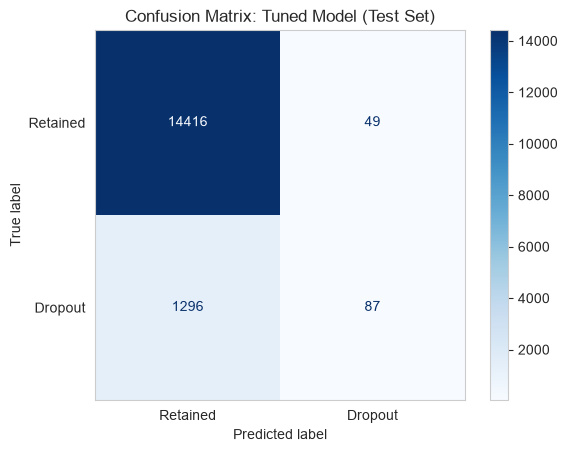

Dropouts correctly flagged (TP): 87
Dropouts missed           (FN): 1296
False alarms              (FP): 49
Correctly left alone      (TN): 14416


In [33]:
# Build the 2x2 matrix from true vs predicted labels
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely with labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained', 'Dropout'])
disp.plot(cmap='Blues', values_format='d')   # 'd' = show whole numbers
plt.title('Confusion Matrix: Tuned Model (Test Set)')
plt.grid(False)
plt.show()

# Unpack the four numbers for a plain-English summary
tn, fp, fn, tp = cm.ravel()   # .ravel() flattens the 2x2 matrix into 4 values
print(f'Dropouts correctly flagged (TP): {tp}')
print(f'Dropouts missed           (FN): {fn}')
print(f'False alarms              (FP): {fp}')
print(f'Correctly left alone      (TN): {tn}')

#### Feature Importance

In [ ]:
# Look at the fitted preprocessor step
full_pipeline.named_steps['preprocessor']

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'first_generation', 'family_income',
                                  'household_size', 'scholarship',
                                  'tuition_base', 'semester', 'course_load',
                                  'work_hours', 'emergency_expense', 'sem_gpa',
                                  'attendance', 'lms_logins', 'advising_visits',
                                  'failed_courses', 'financial_stress']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'housing_status'])])

In [ ]:
# Drill down to the fitted OneHotEncoder and ask for its output column names
ohe_feature_names = (full_pipeline.named_steps['preprocessor']
                     .named_transformers_['cat']
                     .named_steps['onehot']
                     .get_feature_names_out(cat_col))

# The ColumnTransformer outputs numeric columns FIRST, then categorical ones,
# so we join the names in that same order
all_feature_names = num_col + list(ohe_feature_names)

print(f'Total features the model sees: {len(all_feature_names)}')
all_feature_names

Total features the model sees: 23


['age',
 'first_generation',
 'family_income',
 'household_size',
 'scholarship',
 'tuition_base',
 'semester',
 'course_load',
 'work_hours',
 'emergency_expense',
 'sem_gpa',
 'attendance',
 'lms_logins',
 'advising_visits',
 'failed_courses',
 'financial_stress',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'gender_Prefer not to say',
 'housing_status_Off-Campus',
 'housing_status_On-Campus',
 'housing_status_With Parents']

In [ ]:
# Grab the trained model (last step of the pipeline)
model = full_pipeline.named_steps['classifier']

# hasattr() checks whether the object has that attribute
if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_          # tree models
else:
    importances = np.abs(model.coef_[0])              # logistic regression: size of each coefficient

# Put names and scores side by side in a DataFrame, sorted from most to least important
fi_df = (pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
         .sort_values(by='Importance', ascending=False)
         .reset_index(drop=True))

fi_df.head(10)

,Feature,Importance
0,sem_gpa,0.163033
1,financial_stress,0.104833
2,work_hours,0.096701
3,attendance,0.093469
4,family_income,0.089817
5,lms_logins,0.078517
6,failed_courses,0.063253
7,age,0.046122
8,semester,0.041814
9,household_size,0.037027


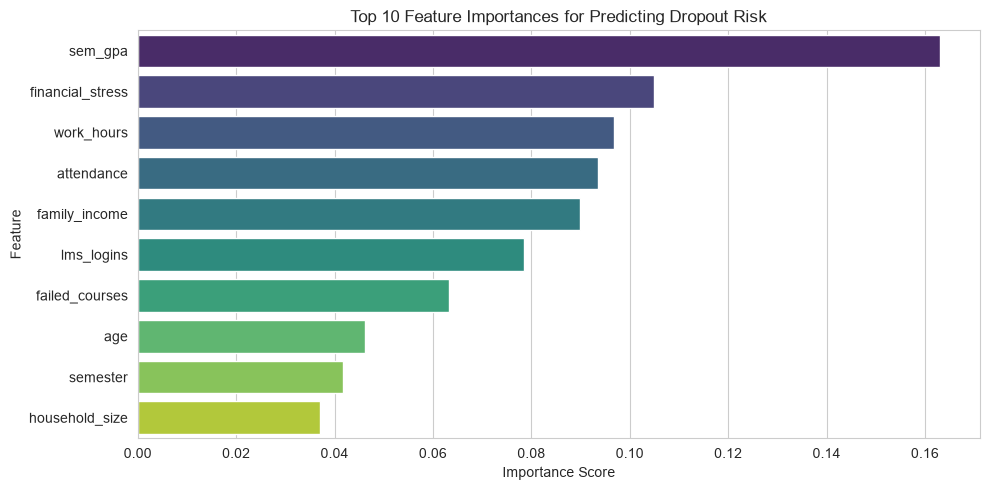

In [ ]:
# Plot the Top 10 most important features
plt.figure(figsize=(10, 5))

# hue='Feature' + legend=False is the modern way to colour bars with a palette
# (the older `palette=` alone triggers a FutureWarning in recent seaborn versions)
sns.barplot(data=fi_df.head(10), x='Importance', y='Feature',
            hue='Feature', palette='viridis', legend=False)

plt.title('Top 10 Feature Importances for Predicting Dropout Risk')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()    # stops labels from being cut off
plt.show()